In [33]:
import yfinance as yf
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

### Loading the data 

In [34]:
pairs = [
    ("KO", "PEP"),
    ("V", "MA"),
    ("SHEL", "BP"),
]

start = "2016-10-20"
split_date = "2022-10-20"
end = "2026-10-20"  

pair_data = {}

for pair in pairs:
    prices = yf.download(
        list(pair),
        start=start,
        end=end,
        auto_adjust=True,
        progress=False,
    )["Close"]
    print(f"{pair}: missing prices")
    print(prices.isna().sum())
    prices = prices.dropna(how="any")

    pair_data[pair] = {
        "train": prices.loc[prices.index < split_date],
        "test": prices.loc[prices.index >= split_date],
    }


('KO', 'PEP'): missing prices
Ticker
KO     0
PEP    0
dtype: int64
('V', 'MA'): missing prices
Ticker
MA    0
V     0
dtype: int64
('SHEL', 'BP'): missing prices
Ticker
BP      0
SHEL    0
dtype: int64


### EDA

Check the sample sizes and price statistics, then compare the training price paths. Missing prices are reported during loading, before incomplete dates are dropped.


KO-PEP
Train observations: 1510 | Test observations: 1002
Duplicate training dates: 0
Ticker       KO      PEP
count   1510.00  1510.00
mean      41.10   107.17
std        7.32    22.71
min       29.71    73.19
25%       34.86    86.80
50%       39.88   106.99
75%       46.39   121.40
max       58.08   156.53


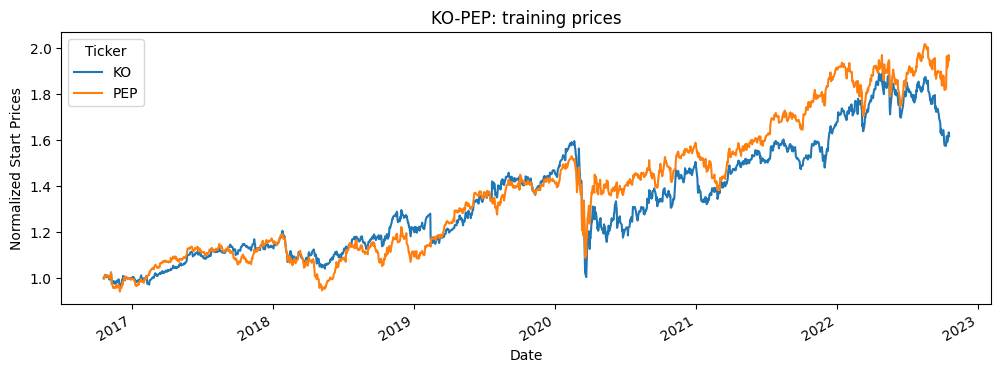

V-MA
Train observations: 1510 | Test observations: 1002
Duplicate training dates: 0
Ticker       MA        V
count   1510.00  1510.00
mean     246.78   158.33
std       87.32    46.60
min       94.49    70.44
25%      171.81   117.65
50%      262.98   168.56
75%      327.18   199.12
max      385.60   241.27


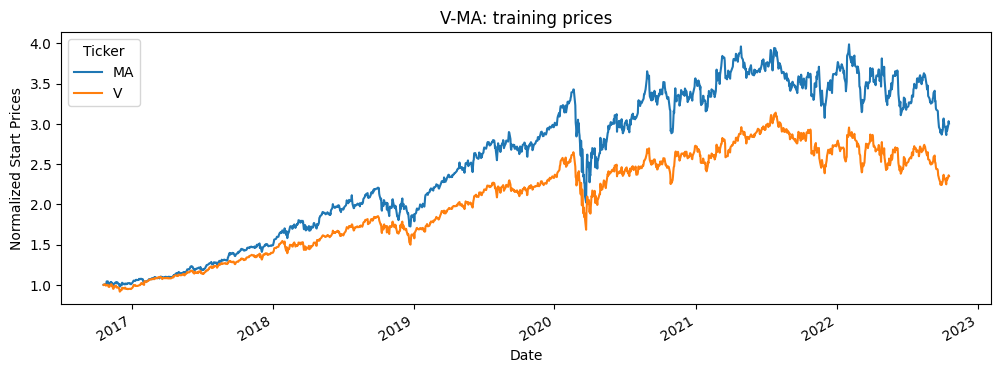

SHEL-BP
Train observations: 1510 | Test observations: 1002
Duplicate training dates: 0
Ticker       BP     SHEL
count   1510.00  1510.00
mean      22.84    38.94
std        4.28     7.73
min       10.96    16.93
25%       20.01    33.41
50%       23.29    41.05
75%       26.30    45.37
max       30.37    52.14


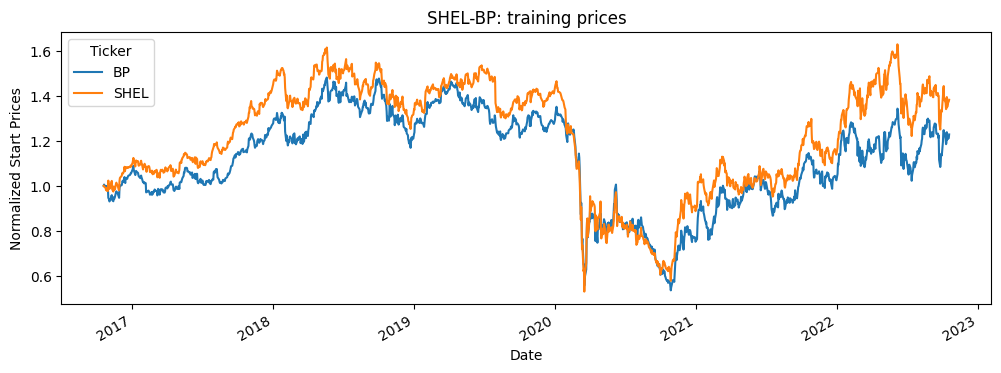

In [35]:
for pair, data in pair_data.items():
    train = data["train"]
    test = data["test"]
    pair_name = f"{pair[0]}-{pair[1]}"

    print(pair_name)
    print("Train observations:", len(train), "| Test observations:", len(test))
    print("Duplicate training dates:", train.index.duplicated().sum())
    print(train.describe().round(2))

    normalized = train / train.iloc[0]
    normalized.plot(figsize=(12, 4), title=f"{pair_name}: training prices")
    plt.ylabel("Normalized Start Prices")
    plt.xlabel("Date")
    plt.show()


### Correlation testing


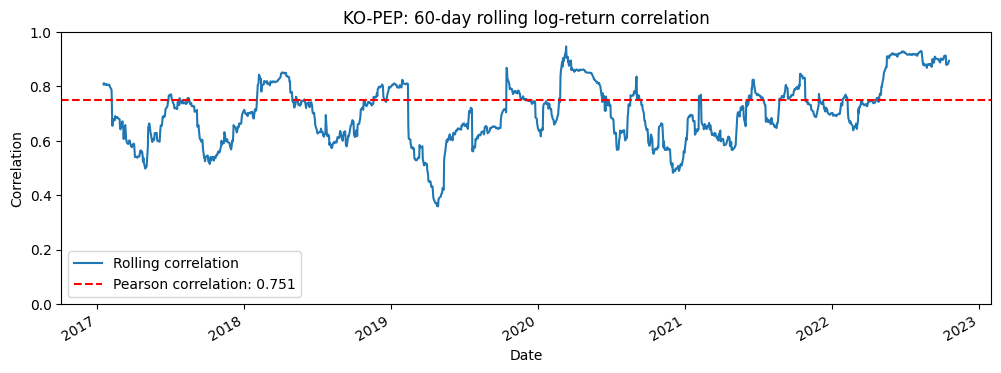

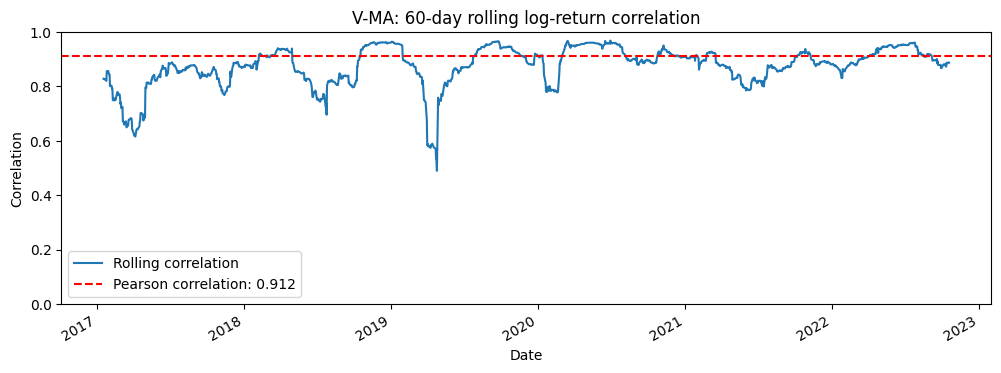

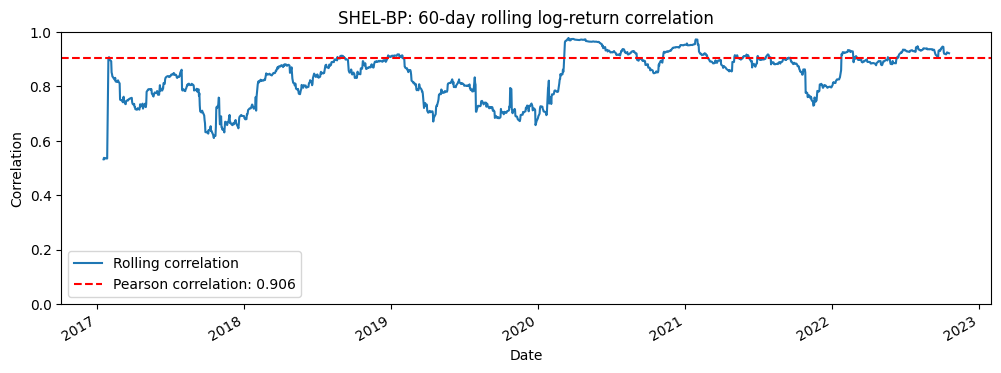

In [36]:
window = 60

for pair, data in pair_data.items():
    train = data["train"]
    returns = np.log(train / train.shift(1)).dropna()
    correlation = returns[pair[0]].corr(returns[pair[1]])
    rolling_correlation = returns[pair[0]].rolling(window).corr(returns[pair[1]])

    rolling_correlation.plot(
        figsize=(12, 4),
        label="Rolling correlation",
        title=f"{pair[0]}-{pair[1]}: {window}-day rolling log-return correlation",
    )
    plt.axhline(correlation, color="red", linestyle="--",
                label=f"Pearson correlation: {correlation:.3f}")
    plt.ylim(0, 1)
    plt.xlabel("Date")
    plt.ylabel("Correlation")
    plt.legend()
    plt.show()


### Performing the cointegration test

In [37]:
ols_models = {}
train_spreads = {}
rows = []

for pair, data in pair_data.items():
    train = data["train"]

    y = train[pair[0]]
    x = train[pair[1]]
    ols = sm.OLS(y, sm.add_constant(x)).fit()

    test_stat, p_value, critical_values = coint(
        y, x, trend="c", method="aeg", autolag="aic"
    )

    ols_models[pair] = ols
    train_spreads[pair] = ols.resid.rename("spread")

    rows.append({
        "pair": f"{pair[0]}-{pair[1]}",
        "intercept": ols.params["const"],
        "beta": ols.params[pair[1]],
        "r_squared": ols.rsquared,
        "EG_p_value": p_value,
    })
summary = pd.DataFrame(rows).set_index("pair")
summary = summary.sort_values("EG_p_value")
print(summary)

         intercept      beta  r_squared  EG_p_value
pair                                               
V-MA     27.255233  0.531129   0.990434    0.002855
SHEL-BP  -0.712179  1.736201   0.923375    0.105938
KO-PEP    7.823820  0.310495   0.928917    0.161977


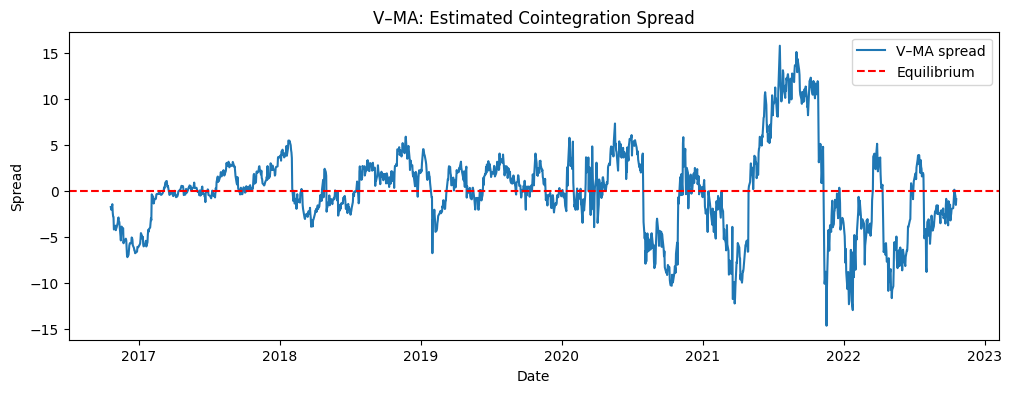

In [38]:
spread = train_spreads[("V", "MA")]

plt.figure(figsize=(12, 4))
plt.plot(spread.index, spread, label="V–MA spread")
plt.axhline(0, color="red", linestyle="--", label="Equilibrium")
plt.title("V–MA: Estimated Cointegration Spread")
plt.xlabel("Date")
plt.ylabel("Spread")
plt.legend()
plt.show()

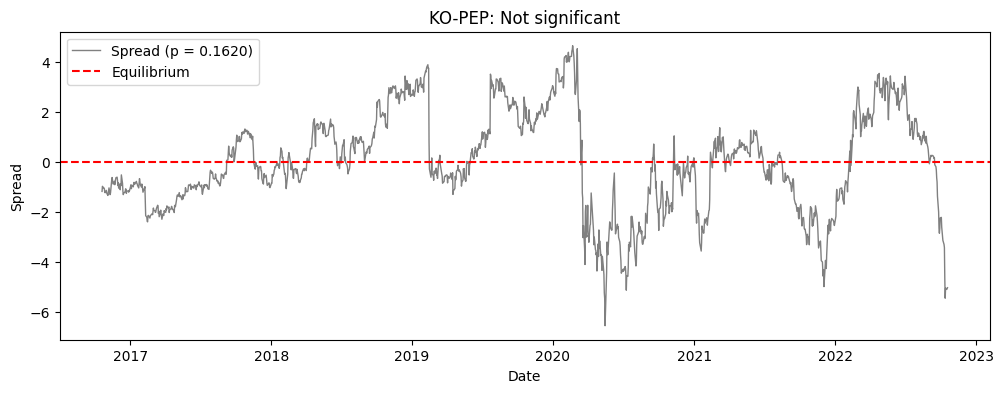

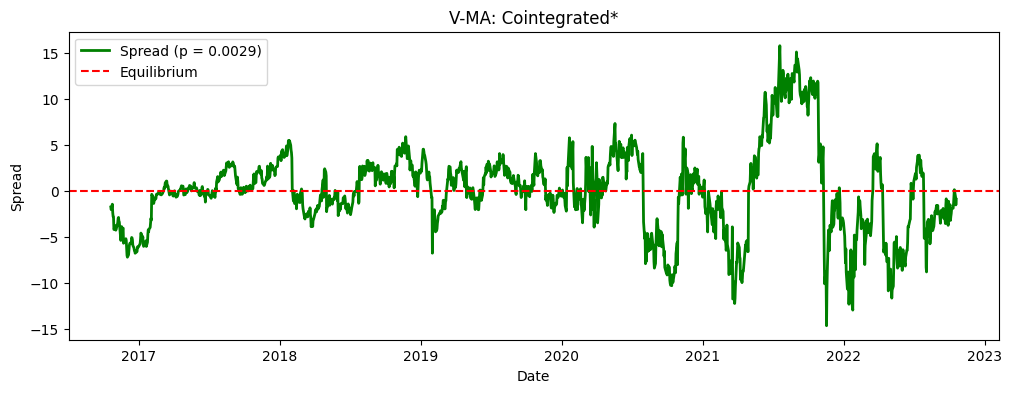

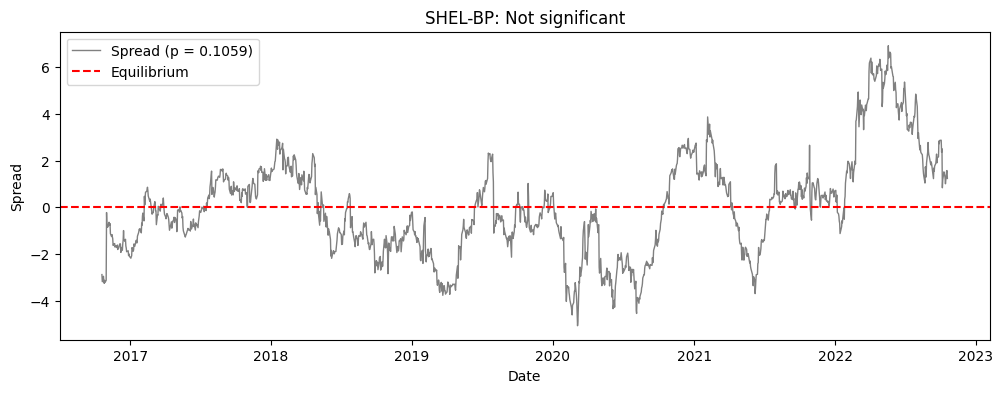

In [39]:
alpha = 0.05

for pair, spread in train_spreads.items():

    pair_name = f"{pair[0]}-{pair[1]}"
    p_value = summary.loc[pair_name, "EG_p_value"]

    significant = p_value < alpha

    color = "green" if significant else "grey"
    status = "Cointegrated*" if significant else "Not significant"

    plt.figure(figsize=(12, 4))
    plt.plot(
        spread.index,
        spread,
        color=color,
        linewidth=2 if significant else 1,
        label=f"Spread (p = {p_value:.4f})"
    )

    plt.axhline(0, color="red", linestyle="--", label="Equilibrium")

    plt.title(f"{pair_name}: {status}")
    plt.xlabel("Date")
    plt.ylabel("Spread")
    plt.legend()
    plt.show()

### Estimate the spread and calculate its z-score


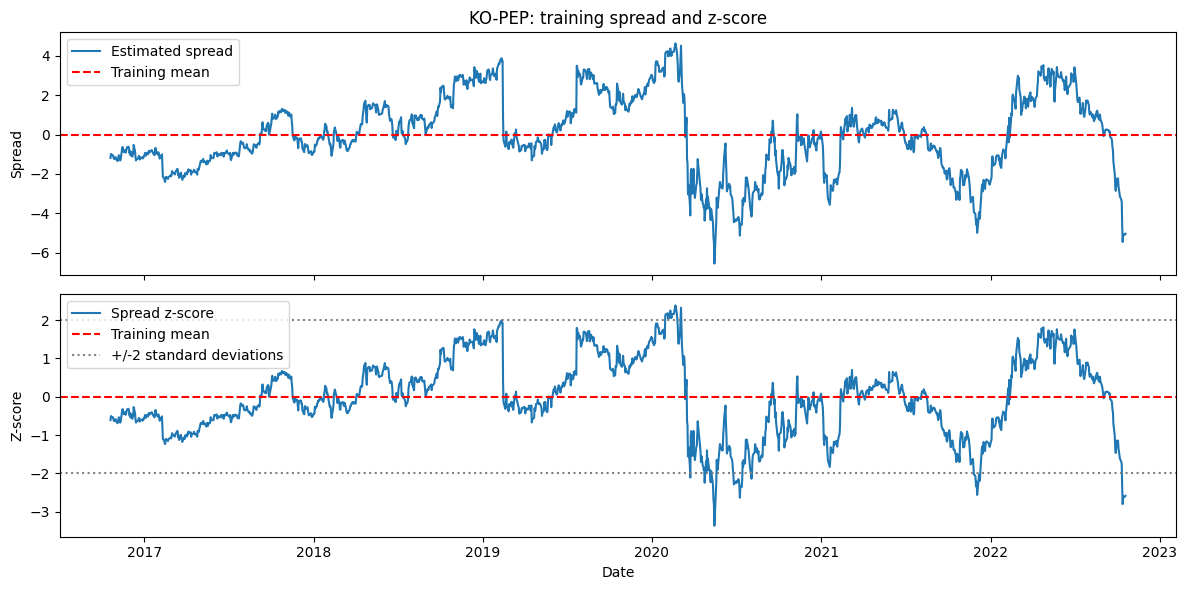

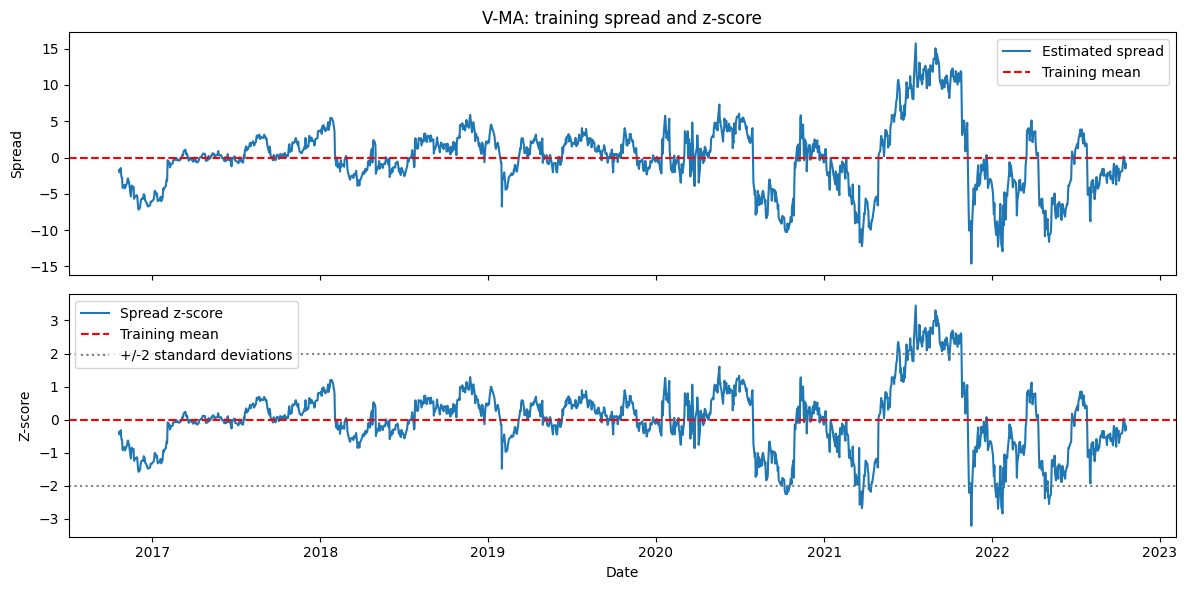

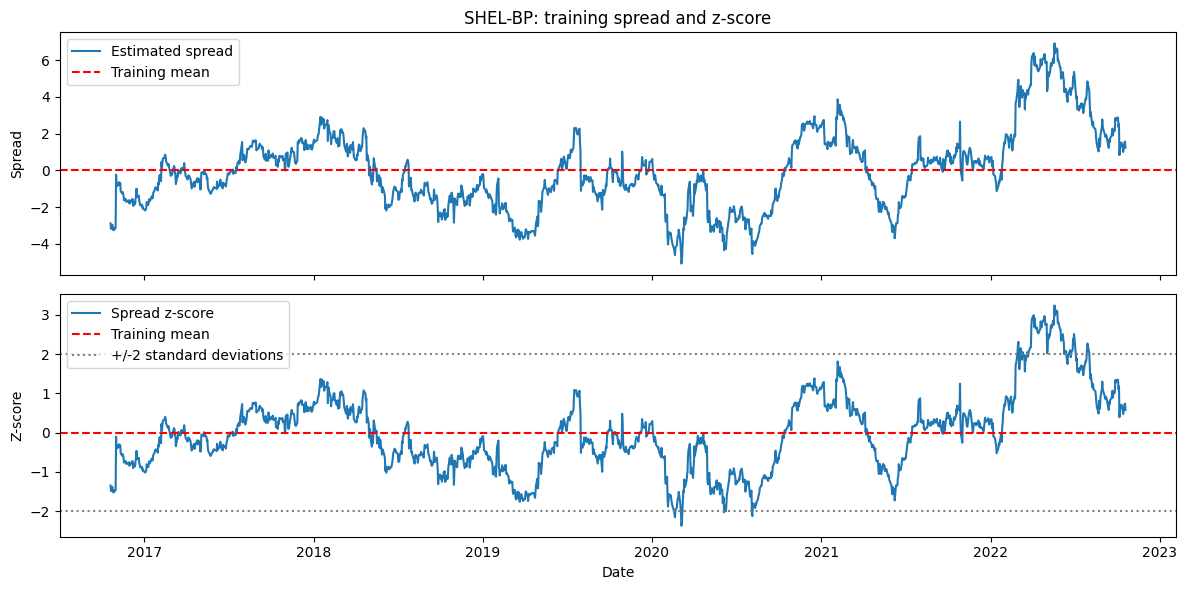

In [40]:
train_z_scores = {}

for pair, spread in train_spreads.items():
    pair_name = f"{pair[0]}-{pair[1]}"

    # The spread was estimated earlier: price A - intercept - beta * price B.
    spread_mean = spread.mean()
    spread_std = spread.std()
    z_score = (spread - spread_mean) / spread_std
    train_z_scores[pair] = z_score

    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

    axes[0].plot(spread.index, spread, label="Estimated spread")
    axes[0].axhline(spread_mean, color="red", linestyle="--", label="Training mean")
    axes[0].set_title(f"{pair_name}: training spread and z-score")
    axes[0].set_ylabel("Spread")
    axes[0].legend()

    axes[1].plot(z_score.index, z_score, label="Spread z-score")
    axes[1].axhline(0, color="red", linestyle="--", label="Training mean")
    axes[1].axhline(2, color="grey", linestyle=":", label="+/-2 standard deviations")
    axes[1].axhline(-2, color="grey", linestyle=":")
    axes[1].set_ylabel("Z-score")
    axes[1].set_xlabel("Date")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


### V–MA: prices and estimated spread


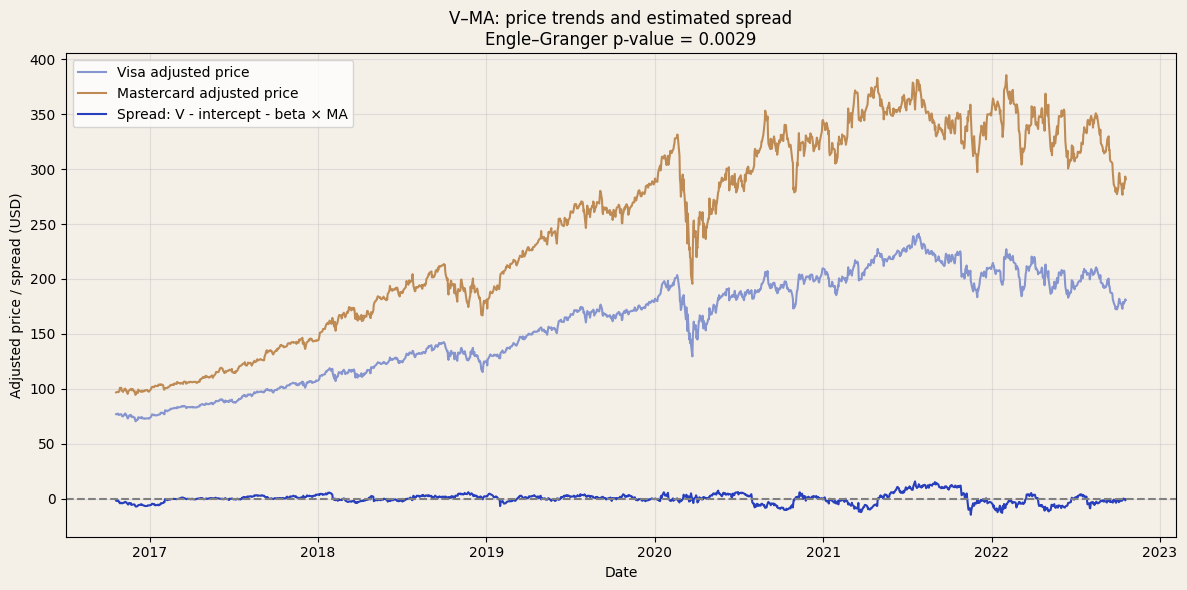

In [41]:
train = pair_data[("V", "MA")]["train"]
spread = train_spreads[("V", "MA")]
p_value = summary.loc["V-MA", "EG_p_value"]

plt.figure(figsize=(12, 6), facecolor="#f4f0e8")
ax = plt.gca()
ax.set_facecolor("#f4f0e8")

plt.plot(train.index, train["V"], color="#8795cf", label="Visa adjusted price")
plt.plot(train.index, train["MA"], color="#bf8b55", label="Mastercard adjusted price")
plt.plot(spread.index, spread, color="#283fbd", label="Spread: V - intercept - beta × MA")
plt.axhline(0, color="grey", linestyle="--")

plt.title(f"V–MA: price trends and estimated spread\nEngle–Granger p-value = {p_value:.4f}")
plt.xlabel("Date")
plt.ylabel("Adjusted price / spread (USD)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
